In [2]:
import os
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

%matplotlib inline

In [11]:
print("pythorch version:", torch.__version__)
print("cuda available:", torch.cuda.is_available())

pythorch version: 2.13.0
cuda available: False


In [10]:
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("Using device:", device)

Using device: mps


In [3]:
#loading the images from the folder

DATA_DIR = "data"
IMG_DIR = os.path.join(DATA_DIR, "images")
MASK_DIR = os.path.join(DATA_DIR, "masks")

In [13]:
df = pd.read_csv(os.path.join(DATA_DIR, "ground_truth.csv"))
print(f'Total images: {len(df)}')
df.head()

Total images: 300


,filename,gate_width_px,gate_pitch_px,gate_height_px,dielectric_thickness_px,metal_top_row_px,corner_blur_sigma
0,sem_0000.png,38,100,27,11,48,3.877
1,sem_0001.png,44,82,27,7,41,4.347
2,sem_0002.png,30,96,19,8,37,3.885
3,sem_0003.png,51,105,20,7,47,4.807
4,sem_0004.png,36,94,26,13,43,4.331


In [14]:
#making the data in the table readable for pythorch, telling the model where to find which data

class SEMDataset(Dataset):
    def __init__(self, filenames, img_dir, mask_dir):
        self.filenames = filenames
        self.img_dir = img_dir
        self.mask_dir = mask_dir

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, idx):
        fname = self.filenames[idx]

        img = cv2.imread(os.path.join(self.img_dir, fname), cv2.IMREAD_GRAYSCALE)
        mask = cv2.imread(os.path.join(self.mask_dir, fname), cv2.IMREAD_GRAYSCALE)

        #normalizing image to [0,1] and adding a channel dimension : (H,W) --> (1,H,W)
        img = img.astype(np.float32) / 255.0
        img = torch.from_numpy(img).unsqueeze(0)

        #mask stays as raw interger class labels
        mask = torch.from_numpy(mask.astype(np.int64))

        return img, mask
        

In [15]:
#checking the process...

test_dataset = SEMDataset(df["filename"].tolist(), IMG_DIR, MASK_DIR)
img, mask = test_dataset[0]

print("Image tensor shape", img.shape, img.dtype)
print("mask tensor shape", mask.shape, mask.dtype)
print("mask unique values", torch.unique(mask))

Image tensor shape torch.Size([1, 256, 384]) torch.float32
mask tensor shape torch.Size([256, 384]) torch.int64
mask unique values tensor([0, 1, 2, 3, 4])


In [19]:
#spliting the data into test, validation and test batches

from sklearn.model_selection import train_test_split

filenames = df["filename"].tolist()

#70% train, 12% validation and 15% test
train_files, temp_files = train_test_split(filenames, test_size=0.3, random_state=42)
val_files, test_files = train_test_split(temp_files, test_size=0.5, random_state=42)

print(f"Train: {len(train_files)}, Val: {len(val_files)}, test: {len(test_files)}")

train_dataset = SEMDataset(train_files, IMG_DIR, MASK_DIR)
val_dataset = SEMDataset(val_files, IMG_DIR, MASK_DIR)
test_dataset = SEMDataset(test_files, IMG_DIR, MASK_DIR)

BATCH_SIZE = 16 

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

Train: 210, Val: 45, test: 45


In [20]:
# now training the U-net

class DoubleConv(nn.Module):
    """Two consecutive conv layers, each followed by BatchNorm + ReLU.
    This is the basic repeated building block used throughout U-Net."""
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, in_channels=1, n_classes=5, base_filters=16):
        super().__init__()

        # ---- Encoder (contracting path) ----
        self.enc1 = DoubleConv(in_channels, base_filters)          # 16
        self.enc2 = DoubleConv(base_filters, base_filters * 2)     # 32
        self.enc3 = DoubleConv(base_filters * 2, base_filters * 4) # 64
        self.pool = nn.MaxPool2d(2)

        # ---- Bottleneck ----
        self.bottleneck = DoubleConv(base_filters * 4, base_filters * 8)  # 128

        # ---- Decoder (expansive path) ----
        self.up3 = nn.ConvTranspose2d(base_filters * 8, base_filters * 4, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(base_filters * 8, base_filters * 4)  # 64+64 -> 64 after concat

        self.up2 = nn.ConvTranspose2d(base_filters * 4, base_filters * 2, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(base_filters * 4, base_filters * 2)  # 32+32 -> 32

        self.up1 = nn.ConvTranspose2d(base_filters * 2, base_filters, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(base_filters * 2, base_filters)      # 16+16 -> 16

        # ---- Final 1x1 conv: maps features -> per-pixel class scores ----
        self.out_conv = nn.Conv2d(base_filters, n_classes, kernel_size=1)

    def forward(self, x):
        # encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        # bottleneck
        b = self.bottleneck(self.pool(e3))

        # decoder, with skip connections (concatenate matching encoder output)
        d3 = self.up3(b)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.out_conv(d1)  # shape: (batch, n_classes, H, W)

In [21]:
model = UNet(in_channels=1, n_classes=5, base_filters=16).to(device)

# test with a dummy batch
dummy_input = torch.randn(2, 1, 256, 384).to(device)
output = model(dummy_input)
print("Output shape:", output.shape)  # expect: (2, 5, 256, 384)

Output shape: torch.Size([2, 5, 256, 384])


In [22]:
#calculating the parameters

n_params = sum(p.numel() for p in model.parameters())
print(f"Total trainable parameters: {n_params:,}")

Total trainable parameters: 483,221


In [23]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [24]:
# now startign the training process

N_EPOCHS = 15

train_losses = []
val_losses = []

for epoch in range(N_EPOCHS):
    # ---- Training phase ----
    model.train()  # tells layers like BatchNorm to behave in "training mode"
    running_train_loss = 0.0

    for img, mask in train_loader:
        img, mask = img.to(device), mask.to(device)

        optimizer.zero_grad()          # clear gradients from the previous step
        output = model(img)            # forward pass: (batch, 5, H, W)
        loss = criterion(output, mask) # compare predictions to ground truth
        loss.backward()                # backward pass: compute gradients
        optimizer.step()               # update weights using those gradients

        running_train_loss += loss.item() * img.size(0)

    epoch_train_loss = running_train_loss / len(train_dataset)
    train_losses.append(epoch_train_loss)

    # ---- Validation phase ----
    model.eval()  # tells layers like BatchNorm to behave in "eval mode"
    running_val_loss = 0.0

    with torch.no_grad():  # no need to track gradients - saves memory/compute
        for img, mask in val_loader:
            img, mask = img.to(device), mask.to(device)
            output = model(img)
            loss = criterion(output, mask)
            running_val_loss += loss.item() * img.size(0)

    epoch_val_loss = running_val_loss / len(val_dataset)
    val_losses.append(epoch_val_loss)

    print(f"Epoch {epoch+1}/{N_EPOCHS} | Train loss: {epoch_train_loss:.4f} | Val loss: {epoch_val_loss:.4f}")

Epoch 1/15 | Train loss: 1.0375 | Val loss: 1.4463
Epoch 2/15 | Train loss: 0.6892 | Val loss: 0.8809
Epoch 3/15 | Train loss: 0.5803 | Val loss: 0.5423
Epoch 4/15 | Train loss: 0.4939 | Val loss: 0.4619
Epoch 5/15 | Train loss: 0.4223 | Val loss: 0.4176
Epoch 6/15 | Train loss: 0.3587 | Val loss: 0.3672
Epoch 7/15 | Train loss: 0.3048 | Val loss: 0.3025
Epoch 8/15 | Train loss: 0.2580 | Val loss: 0.2481
Epoch 9/15 | Train loss: 0.2193 | Val loss: 0.2128
Epoch 10/15 | Train loss: 0.1873 | Val loss: 0.1821
Epoch 11/15 | Train loss: 0.1622 | Val loss: 0.1400
Epoch 12/15 | Train loss: 0.1392 | Val loss: 0.1301
Epoch 13/15 | Train loss: 0.1209 | Val loss: 0.1198
Epoch 14/15 | Train loss: 0.1047 | Val loss: 0.1059
Epoch 15/15 | Train loss: 0.0933 | Val loss: 0.1465


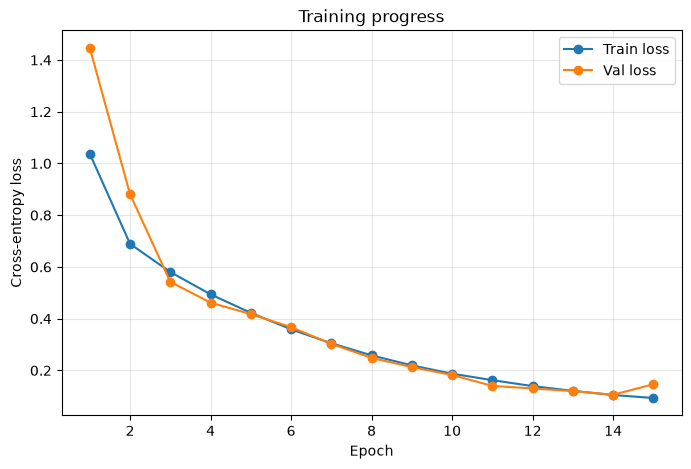

In [25]:
# visualizing the loss curves

plt.figure(figsize=(8, 5))
plt.plot(range(1, N_EPOCHS+1), train_losses, label="Train loss", marker='o')
plt.plot(range(1, N_EPOCHS+1), val_losses, label="Val loss", marker='o')
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Training progress")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# we can see both the loss curves are decreasing hugging each other. The small bump at the the end
# may be due to small noise

In [28]:
from matplotlib.colors import ListedColormap, BoundaryNorm

class_colors = ['black', 'khaki', 'white', 'steelblue', 'gray']
cmap = ListedColormap(class_colors)
norm = BoundaryNorm(boundaries=np.arange(-0.5, 5, 1), ncolors=5)

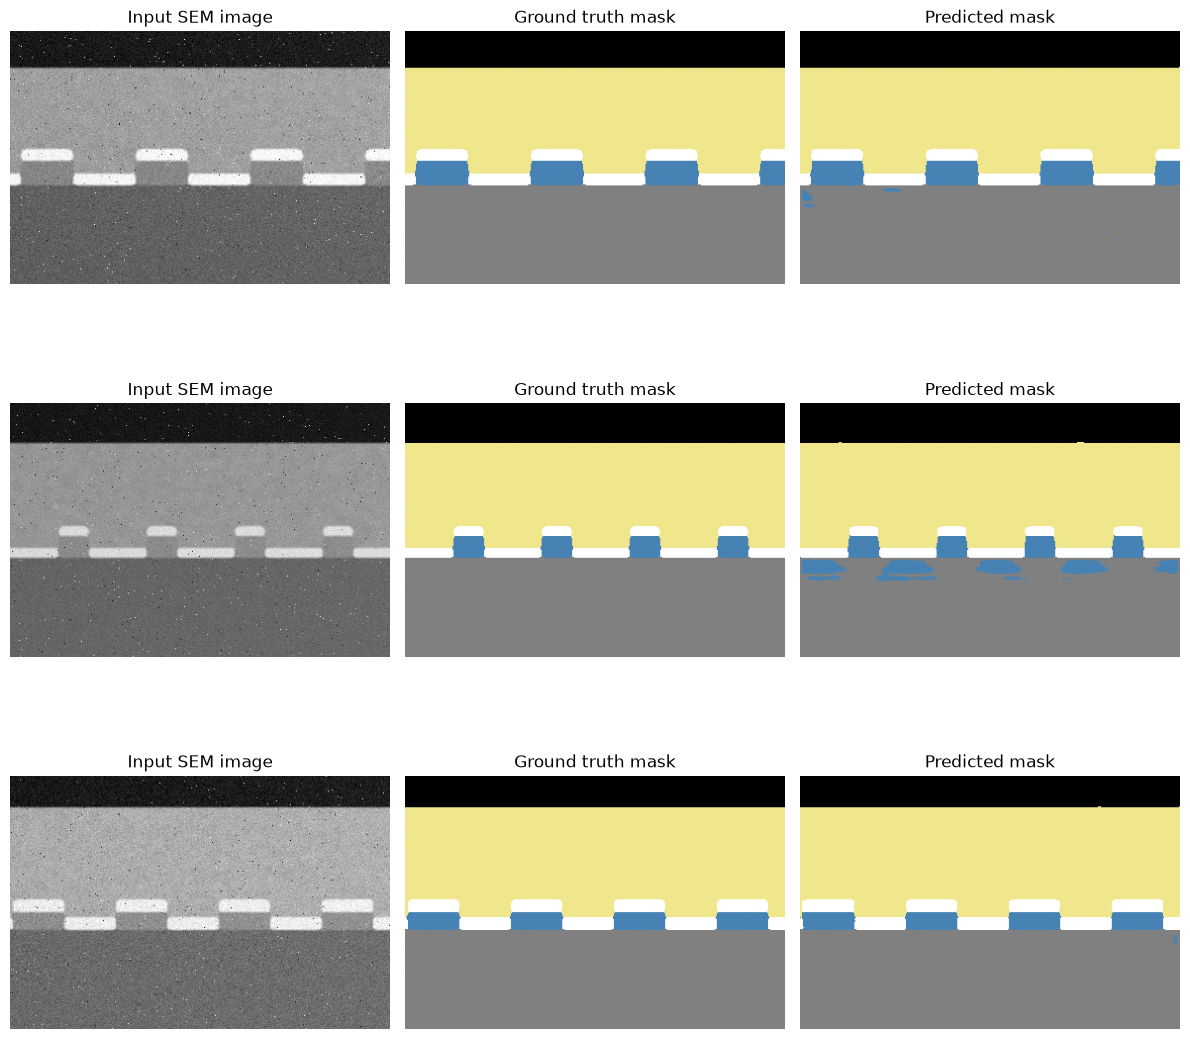

In [29]:
model.eval()

def predict_mask(model, img_tensor):
    """Run one image through the model and return the predicted class mask."""
    with torch.no_grad():
        img_tensor = img_tensor.unsqueeze(0).to(device)  # add batch dim
        output = model(img_tensor)                        # (1, 5, H, W)
        pred = torch.argmax(output, dim=1)                 # (1, H, W) - pick highest-scoring class per pixel
        pred = pred.squeeze(0).cpu().numpy()                # back to (H, W) numpy array
    return pred


# pick a few validation images to visualize
sample_indices = [0, 5, 10]

fig, axes = plt.subplots(len(sample_indices), 3, figsize=(12, 4 * len(sample_indices)))

for row, idx in enumerate(sample_indices):
    img_tensor, true_mask = val_dataset[idx]
    pred_mask = predict_mask(model, img_tensor)

    img_np = img_tensor.squeeze(0).numpy()

    axes[row, 0].imshow(img_np, cmap='gray')
    axes[row, 0].set_title("Input SEM image")
    axes[row, 0].axis('off')

    axes[row, 1].imshow(true_mask.numpy(), cmap=cmap, norm=norm)
    axes[row, 1].set_title("Ground truth mask")
    axes[row, 1].axis('off')

    axes[row, 2].imshow(pred_mask, cmap=cmap, norm=norm)
    axes[row, 2].set_title("Predicted mask")
    axes[row, 2].axis('off')

plt.tight_layout()
plt.show()

In [30]:
# CD measurements from the predicted mask

def measure_gate_cds(mask, gate_class=3, silicon_class=4):
    """
    Given a predicted (or ground truth) label mask, measure:
      - gate width (average width of each gate 'blob', in pixels)
      - gate pitch (average center-to-center spacing between gates)
      - gate height (average vertical extent of gate pixels)
    by scanning the row where gates sit (just above the silicon surface).
    """
    # find the topmost row of silicon -> gates sit just above this
    silicon_rows = np.where(mask == silicon_class)[0]
    if len(silicon_rows) == 0:
        return None  # silicon not found - can't measure
    si_top_row = silicon_rows.min()

    # scan a horizontal line just above the silicon surface to find gate segments
    scan_row = mask[si_top_row - 2, :]  # 2px above silicon surface
    is_gate = (scan_row == gate_class)

    # find contiguous runs of True (each run = one gate finger)
    edges = np.diff(is_gate.astype(int))
    starts = np.where(edges == 1)[0] + 1
    ends = np.where(edges == -1)[0] + 1
    if is_gate[0]:
        starts = np.insert(starts, 0, 0)
    if is_gate[-1]:
        ends = np.append(ends, len(is_gate))

    if len(starts) == 0:
        return None  # no gates detected

    widths = ends - starts
    centers = (starts + ends) / 2
    pitches = np.diff(centers) if len(centers) > 1 else np.array([])

    # gate height: for each detected gate column, count vertical extent of gate class
    heights = []
    for s, e in zip(starts, ends):
        col_center = (s + e) // 2
        col = mask[:, col_center]
        gate_pixels = np.where(col == gate_class)[0]
        if len(gate_pixels) > 0:
            heights.append(gate_pixels.max() - gate_pixels.min() + 1)

    return {
        "gate_width_px": np.mean(widths) if len(widths) > 0 else None,
        "gate_pitch_px": np.mean(pitches) if len(pitches) > 0 else None,
        "gate_height_px": np.mean(heights) if len(heights) > 0 else None,
        "n_gates_detected": len(starts),
    }

In [31]:
idx = 0
fname = val_files[idx]
img_tensor, true_mask_tensor = val_dataset[idx]
pred_mask = predict_mask(model, img_tensor)
true_mask = true_mask_tensor.numpy()

pred_cds = measure_gate_cds(pred_mask)
true_cds = measure_gate_cds(true_mask)

gt_row = df[df["filename"] == fname].iloc[0]

print(f"File: {fname}")
print(f"Ground truth CSV        -> gate_width: {gt_row['gate_width_px']}, gate_pitch: {gt_row['gate_pitch_px']}, gate_height: {gt_row['gate_height_px']}")
print(f"Measured from TRUE mask -> {true_cds}")
print(f"Measured from PRED mask -> {pred_cds}")

File: sem_0045.png
Ground truth CSV        -> gate_width: 53, gate_pitch: 116, gate_height: 25
Measured from TRUE mask -> {'gate_width_px': np.float64(46.0), 'gate_pitch_px': np.float64(111.33333333333333), 'gate_height_px': np.float64(25.0), 'n_gates_detected': 4}
Measured from PRED mask -> {'gate_width_px': np.float64(46.0), 'gate_pitch_px': np.float64(111.33333333333333), 'gate_height_px': np.float64(25.0), 'n_gates_detected': 4}


In [32]:
#point to note that the rounding corner effect has made the gate width lesser 


In [33]:
#now feeding all the images and testing accuracy

results = []

for fname in test_files:
    idx = test_files.index(fname)
    img_tensor, true_mask_tensor = test_dataset[idx]
    pred_mask = predict_mask(model, img_tensor)
    true_mask = true_mask_tensor.numpy()

    true_cds = measure_gate_cds(true_mask)
    pred_cds = measure_gate_cds(pred_mask)

    if true_cds is None or pred_cds is None:
        continue  # skip if measurement failed (e.g. no gates detected)

    row = {"filename": fname}
    for key in ["gate_width_px", "gate_pitch_px", "gate_height_px"]:
        true_val = true_cds[key]
        pred_val = pred_cds[key]
        if true_val is None or pred_val is None or true_val == 0:
            row[key + "_true"] = true_val
            row[key + "_pred"] = pred_val
            row[key + "_pct_error"] = None
        else:
            row[key + "_true"] = true_val
            row[key + "_pred"] = pred_val
            row[key + "_pct_error"] = abs(pred_val - true_val) / true_val * 100

    results.append(row)

results_df = pd.DataFrame(results)
results_df.head(10)

,filename,gate_width_px_true,gate_width_px_pred,gate_width_px_pct_error,gate_pitch_px_true,gate_pitch_px_pred,gate_pitch_px_pct_error,gate_height_px_true,gate_height_px_pred,gate_height_px_pct_error
0,sem_0093.png,41.600000,41.400000,0.480769,89.500000,89.500000,0.0,22.000000,31.200000,41.818182
1,sem_0249.png,39.250000,39.250000,0.000000,105.500000,105.500000,0.0,29.000000,29.000000,0.000000
2,sem_0278.png,36.750000,36.750000,0.000000,104.833333,104.833333,0.0,25.000000,25.000000,0.000000
3,sem_0108.png,34.000000,34.000000,0.000000,73.600000,73.600000,0.0,24.500000,22.500000,8.163265
4,sem_0203.png,36.750000,36.750000,0.000000,101.833333,101.833333,0.0,20.000000,20.000000,0.000000
5,sem_0281.png,52.500000,52.500000,0.000000,101.666667,101.666667,0.0,29.000000,29.000000,0.000000
6,sem_0073.png,32.333333,32.000000,1.030928,73.800000,73.800000,0.0,28.000000,28.000000,0.000000
7,sem_0030.png,40.000000,40.000000,0.000000,80.375000,80.375000,0.0,20.000000,20.000000,0.000000
8,sem_0237.png,28.166667,28.166667,0.000000,74.300000,74.300000,0.0,27.833333,27.166667,2.395210
9,sem_0077.png,35.000000,35.000000,0.000000,87.250000,87.250000,0.0,21.000000,21.000000,0.000000


In [34]:
print("Mean % error per CD:")
for key in ["gate_width_px", "gate_pitch_px", "gate_height_px"]:
    col = key + "_pct_error"
    print(f"  {key}: {results_df[col].mean():.2f}%  (median: {results_df[col].median():.2f}%)")

print(f"\nImages successfully measured: {len(results_df)} / {len(test_files)}")

Mean % error per CD:
  gate_width_px: 0.30%  (median: 0.00%)
  gate_pitch_px: 0.02%  (median: 0.00%)
  gate_height_px: 1.32%  (median: 0.00%)

Images successfully measured: 45 / 45


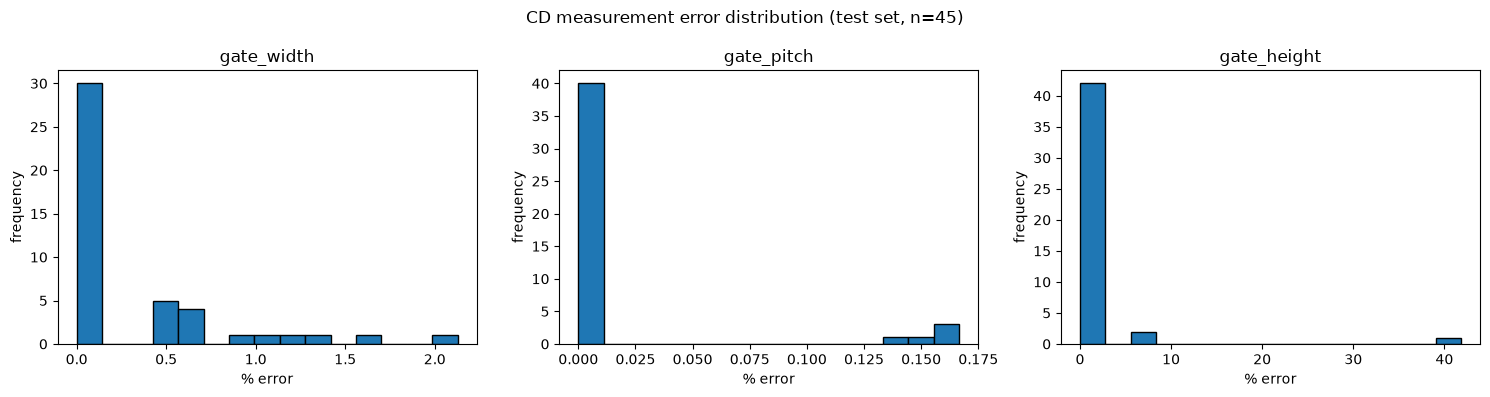

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
cd_names = ["gate_width_px", "gate_pitch_px", "gate_height_px"]

for ax, key in zip(axes, cd_names):
    col = key + "_pct_error"
    ax.hist(results_df[col].dropna(), bins=15, edgecolor='black')
    ax.set_title(key.replace("_px", ""))
    ax.set_xlabel("% error")
    ax.set_ylabel("frequency")

plt.suptitle("CD measurement error distribution (test set, n=45)")
plt.tight_layout()
plt.show()

In [39]:
# recreate the architecture first (must match exactly: same in_channels, n_classes, base_filters)
loaded_model = UNet(in_channels=1, n_classes=5, base_filters=16).to(device)

# load the saved weights into it
loaded_model.load_state_dict(torch.load(os.path.join(MODEL_DIR, "unet_sem_cd.pth"), map_location=device))

loaded_model.eval()  # set to eval mode before using for predictions
print("Model loaded and ready.")

Model loaded and ready.


In [38]:
import os

MODEL_DIR = "models"
os.makedirs(MODEL_DIR, exist_ok=True)

model_path = os.path.join(MODEL_DIR, "unet_sem_cd.pth")
torch.save(model.state_dict(), model_path)

print(f"Model saved to: {model_path}")

Model saved to: models/unet_sem_cd.pth
